# Partie 1 — Modèles de base entraînés de zéro

**Projet DiagnoCulture** — diagnostic des maladies de la tomate (10 classes, PlantVillage, 128×128).

Ce notebook couvre les 6 points de la Partie 1 : (1) rechargement des données figées, (2) **CNN-Plain**, (3) **CNN-Res** (connexions résiduelles + GAP), (4) étude d'un hyperparamètre, (5) diagnostic des gradients, (6) tableau comparatif. Le découpage train/val/test et les statistiques de normalisation proviennent du notebook `00_eda_split` (fichiers sur Drive). **Le jeu de test n'est utilisé qu'une seule fois par modèle final.**

## 0. Configuration, données et reproductibilité

**Installation des dépendances** (seul `torchinfo` n'est pas préinstallé sur Colab).

In [2]:
!pip install -q torchinfo

**Imports — tous regroupés ici.**

In [3]:
# ---- Imports----
import os, json, copy, time, random
import numpy as np
import pandas as pd
from collections import defaultdict

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from torchinfo import summary

import kagglehub
from google.colab import drive

**Reproductibilité.** On fixe toutes les graines (Python, NumPy, PyTorch) et on force cuDNN en mode déterministe, pour des résultats reproductibles d'une exécution à l'autre.

In [4]:
def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

**Montage de Google Drive (stockage persistant) et téléchargement du dataset via kagglehub.** Le cache kagglehub est temporaire ; seuls les fichiers sur Drive persistent d'une session à l'autre.

In [5]:
drive.mount('/content/drive')

ROOT    = "/content/drive/MyDrive/Project_clean"
DATA    = os.path.join(ROOT, "data")       # split.csv, norm_stats.json
MODELS  = os.path.join(ROOT, "models")     # modèles .pt
RESULTS = os.path.join(ROOT, "results")    # figures .png
for d in (DATA, MODELS, RESULTS): os.makedirs(d, exist_ok=True)

base = kagglehub.dataset_download("emmarex/plantdisease")
print("Dataset :", base)

Mounted at /content/drive
Using Colab cache for faster access to the 'plantdisease' dataset.
Dataset : /kaggle/input/plantdisease


**Détection de la racine des classes** (`.../PlantVillage/Tomato…`) et liste triée des 10 classes.

In [6]:
# arborescence du dataset : .../PlantVillage/Tomato...
DATA_ROOT = None
for r, d, _ in os.walk(base):
    if any(x.startswith("Tomato") for x in d):
        DATA_ROOT = r
        break

classes = sorted(c for c in os.listdir(DATA_ROOT) if c.startswith("Tomato"))
print("DATA_ROOT =", DATA_ROOT)
print(len(classes), "classes Tomato")

DATA_ROOT = /kaggle/input/plantdisease/PlantVillage
10 classes Tomato


**Résultat.** 10 classes `Tomato` détectées (9 maladies + feuilles saines).

**Rechargement du découpage figé (`split.csv`) et des statistiques de normalisation (`norm_stats.json`)** depuis Drive — c'est le pont avec le notebook `00`.

In [7]:
clean_data = pd.read_csv(os.path.join(DATA, "split.csv"))
with open(os.path.join(DATA, "norm_stats.json")) as f:
    stats = json.load(f)
mean, std = stats["mean"], stats["std"]
print(clean_data.shape, "| mean:", mean, "| std:", std)

(15997, 4) | mean: [0.4510954204684638, 0.4649513691038557, 0.4072063214449523] | std: [0.1781187912422103, 0.15549914738434029, 0.1930529174089212]


**Résultat.** 15 997 images (après déduplication anti-fuite) et les stats de normalisation calculées sur le train uniquement, prêtes à l'emploi.

## 1. Dataset & DataLoader PyTorch

On emballe les images dans un `Dataset` (`LeafDataset`) + des `DataLoader`. Augmentation (miroir horizontal) **sur le train uniquement**.

**Définition du `LeafDataset`.** Reconstruit le chemin absolu (`DATA_ROOT` + chemin relatif), redimensionne, normalise (+ miroir horizontal pour le train).

In [8]:
class LeafDataset(Dataset):
    def __init__(self, df, split, img_size, mean, std, augment=False):
        self.df = df[df["split"] == split].reset_index(drop=True)

        tfms = [transforms.Resize((img_size, img_size))]
        if augment:                                   # train uniquement
            tfms += [transforms.RandomHorizontalFlip()]
        tfms += [
            transforms.ToTensor(),
            transforms.Normalize(mean, std),
        ]
        self.tf = transforms.Compose(tfms)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(os.path.join(DATA_ROOT, row["path"])).convert("RGB")  # relatif -> absolu
        x = self.tf(img)
        y = int(row["class_idx"])
        return x, y

**Création des `Dataset` et `DataLoader`** (augmentation sur le train seulement ; `num_workers=2` + `pin_memory=True` pour accélérer l'alimentation du GPU).

In [9]:
IMG = 128   # résolution des CNN maison

train_ds = LeafDataset(clean_data, "train", IMG, mean, std, augment=True)
val_ds   = LeafDataset(clean_data, "val",   IMG, mean, std, augment=False)
test_ds  = LeafDataset(clean_data, "test",  IMG, mean, std, augment=False)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

**Vérification d'un batch.**

In [10]:
images, labels = next(iter(train_loader))
print(images.shape, labels.shape)

torch.Size([32, 3, 128, 128]) torch.Size([32])


**Résultat.** Un batch = `torch.Size([32, 3, 128, 128])` + `[32]` labels : format `(N, C, H, W)` attendu par le CNN.

## 2. CNN-Plain (6 convolutions)

**Architecture.** 6 blocs `Conv(3×3, padding 1) → BatchNorm → ReLU → MaxPool(2)`, puis tête dense `1024 → 256 → 10` avec Dropout 0,5.

*Justification des choix :* noyau **3×3** (petit champ réceptif empilé, standard et efficace en paramètres) ; **padding 1** pour que la convolution conserve la taille (seul le MaxPool réduit) ; nombre de filtres **croissant** (32→256) pour compenser la perte de résolution par de la richesse sémantique ; **BatchNorm** pour stabiliser l'entraînement ; **Dropout** sur la tête dense contre le sur-apprentissage.

In [11]:
class CNNPlain(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        # 6 convolutions : noyau 3, padding 1 -> la conv conserve la taille
        self.conv1 = nn.Conv2d(3,   32,  kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32,  64,  kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64,  128, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.conv5 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.conv6 = nn.Conv2d(256, 256, kernel_size=3, padding=1)

        # une BatchNorm par conv normaliser
        self.bn1 = nn.BatchNorm2d(32)
        self.bn2 = nn.BatchNorm2d(64)
        self.bn3 = nn.BatchNorm2d(128)
        self.bn4 = nn.BatchNorm2d(128)
        self.bn5 = nn.BatchNorm2d(256)
        self.bn6 = nn.BatchNorm2d(256)

        self.pool    = nn.MaxPool2d(2)   # divise la taille par 2
        self.relu    = nn.ReLU()
        self.flatten = nn.Flatten()

        # tête dense : 256 canaux * 2 * 2 = 1024
        self.fc1     = nn.Linear(256 * 2 * 2, 256)
        self.dropout = nn.Dropout(0.5)
        self.fc2     = nn.Linear(256, num_classes)

    def forward(self, x):
        # entrée : (N, 3, 128, 128)
        x = self.pool(self.relu(self.bn1(self.conv1(x))))   # -> (N,  32, 64, 64)
        x = self.pool(self.relu(self.bn2(self.conv2(x))))   # -> (N,  64, 32, 32)
        x = self.pool(self.relu(self.bn3(self.conv3(x))))   # -> (N, 128, 16, 16)
        x = self.pool(self.relu(self.bn4(self.conv4(x))))   # -> (N, 128,  8,  8)
        x = self.pool(self.relu(self.bn5(self.conv5(x))))   # -> (N, 256,  4,  4)
        x = self.pool(self.relu(self.bn6(self.conv6(x))))   # -> (N, 256,  2,  2)

        x = self.flatten(x)              # -> (N, 1024)
        x = self.relu(self.fc1(x))       # -> (N, 256)
        x = self.dropout(x)
        x = self.fc2(x)                  # -> (N, 10)
        return x

model = CNNPlain()

**Calcul des dimensions à la main.**

Convolution `k=3, p=1, s=1` → taille inchangée ; chaque `MaxPool(2)` divise la taille par 2.

| Étape        | Canaux | Taille spatiale |
|--------------|--------|-----------------|
| entrée       | 3      | 128×128         |
| bloc 1 (+pool) | 32   | 64×64           |
| bloc 2 (+pool) | 64   | 32×32           |
| bloc 3 (+pool) | 128  | 16×16           |
| bloc 4 (+pool) | 128  | 8×8             |
| bloc 5 (+pool) | 256  | 4×4             |
| bloc 6 (+pool) | 256  | 2×2             |
| flatten      | —      | 256×2×2 = **1024** |
| fc1          | —      | 256             |
| fc2 (sortie) | —      | 10              |

Ces dimensions sont confirmées par `torchinfo` ci-dessous.

**Résumé des dimensions et du nombre de paramètres (`torchinfo`).**

In [12]:
summary(model, input_size=(1, 3, 128, 128))

Layer (type:depth-idx)                   Output Shape              Param #
CNNPlain                                 [1, 10]                   --
├─Conv2d: 1-1                            [1, 32, 128, 128]         896
├─BatchNorm2d: 1-2                       [1, 32, 128, 128]         64
├─ReLU: 1-3                              [1, 32, 128, 128]         --
├─MaxPool2d: 1-4                         [1, 32, 64, 64]           --
├─Conv2d: 1-5                            [1, 64, 64, 64]           18,496
├─BatchNorm2d: 1-6                       [1, 64, 64, 64]           128
├─ReLU: 1-7                              [1, 64, 64, 64]           --
├─MaxPool2d: 1-8                         [1, 64, 32, 32]           --
├─Conv2d: 1-9                            [1, 128, 32, 32]          73,856
├─BatchNorm2d: 1-10                      [1, 128, 32, 32]          256
├─ReLU: 1-11                             [1, 128, 32, 32]          --
├─MaxPool2d: 1-12                        [1, 128, 16, 16]          --
├─Co

**Résultat.** **1,39 M paramètres (~5,6 Mo)**, concentrés dans les deux dernières convolutions et la couche dense `1024→256`. Les dimensions descendent bien de (3, 128, 128) à (256, 2, 2) puis 10 sorties — conformes au calcul manuel.

**Préparation de l'entraînement.** Device (GPU si dispo), perte `CrossEntropyLoss`, optimiseur `Adam` (lr = 1e-3).

In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
print("device:", device)

criterion = nn.CrossEntropyLoss()                        # perte pour classif multi-classes
optimizer = optim.Adam(model.parameters(), lr=1e-3)      # optimiseur robuste, lr standard

device: cuda


**Résultat.** `device: cuda` → entraînement sur le **GPU Colab (T4)**.

**Entraînement train/val avec early-stopping** (patience 5). On garde les meilleurs poids (plus basse val_loss) et on les sauvegarde sur Drive.

In [14]:
set_seed(42)     # reproductibilité (init des poids + shuffle)

EPOCHS   = 30
PATIENCE = 5               # on arrête si val_loss ne s'améliore plus pendant 5 epochs

history = {"train_loss": [], "val_loss": [], "val_acc": []}
best_val_loss = float("inf")
best_weights  = copy.deepcopy(model.state_dict())
patience_cnt  = 0

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    # ---------- TRAIN ----------
    model.train()
    running = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        running += loss.item() * x.size(0)
    train_loss = running / len(train_loader.dataset)

    # ---------- VALIDATION ----------
    model.eval()
    v_running, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            v_running += criterion(out, y).item() * x.size(0)
            correct   += (out.argmax(1) == y).sum().item()
            total     += y.size(0)
    val_loss = v_running / len(val_loader.dataset)
    val_acc  = correct / total

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    print(f"Epoch {epoch:2d} | train {train_loss:.4f} | val {val_loss:.4f} | val_acc {val_acc:.3f} | {time.time()-t0:.0f}s")

    # ---------- EARLY-STOPPING ----------
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights  = copy.deepcopy(model.state_dict())
        patience_cnt  = 0
    else:
        patience_cnt += 1
        if patience_cnt >= PATIENCE:
            print(f"Early-stopping à l'epoch {epoch}")
            break

model.load_state_dict(best_weights)                       # on restaure le meilleur modèle
torch.save(best_weights, os.path.join(MODELS, "cnn_plain_best.pt"))   # sauvé sur Drive
print("Meilleur val_loss :", round(best_val_loss, 4))

Epoch  1 | train 0.9720 | val 0.4421 | val_acc 0.841 | 47s
Epoch  2 | train 0.5242 | val 0.3179 | val_acc 0.893 | 27s
Epoch  3 | train 0.4025 | val 0.4231 | val_acc 0.865 | 29s
Epoch  4 | train 0.3362 | val 0.2894 | val_acc 0.896 | 27s
Epoch  5 | train 0.3042 | val 0.2913 | val_acc 0.898 | 27s
Epoch  6 | train 0.2516 | val 0.2360 | val_acc 0.922 | 27s
Epoch  7 | train 0.2215 | val 0.1709 | val_acc 0.938 | 28s
Epoch  8 | train 0.1988 | val 0.1818 | val_acc 0.941 | 27s
Epoch  9 | train 0.1901 | val 0.1204 | val_acc 0.961 | 27s
Epoch 10 | train 0.1433 | val 0.1330 | val_acc 0.958 | 27s
Epoch 11 | train 0.1475 | val 0.2009 | val_acc 0.938 | 27s
Epoch 12 | train 0.1576 | val 0.1270 | val_acc 0.956 | 27s
Epoch 13 | train 0.1309 | val 0.1218 | val_acc 0.959 | 27s
Epoch 14 | train 0.1377 | val 0.2984 | val_acc 0.918 | 27s
Early-stopping à l'epoch 14
Meilleur val_loss : 0.1204


**Résultat.** Convergence propre : train et val descendent ensemble. Meilleur **val_loss 0,1204** (val_acc ≈ 0,961), early-stopping à l'epoch 14. Le pic de val à l'epoch 14 est du **bruit de validation** normal, pas du sur-apprentissage.

**Courbes d'apprentissage.**

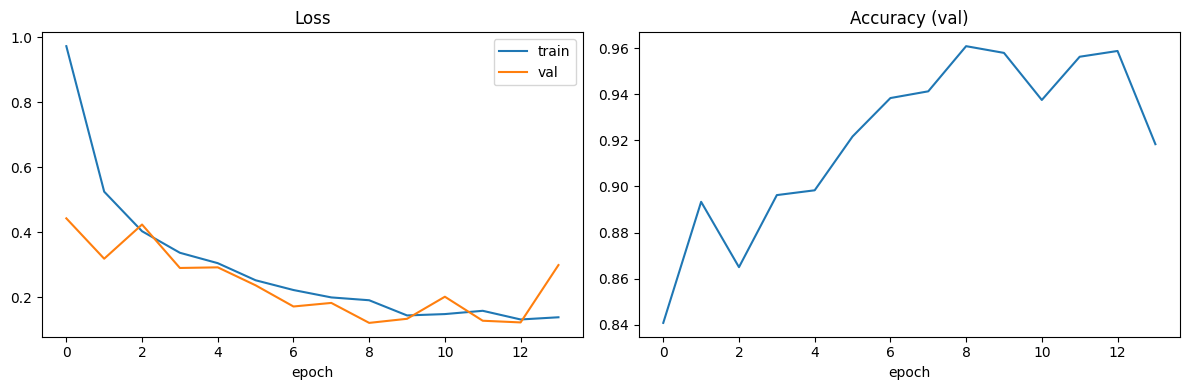

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history["train_loss"], label="train")
ax1.plot(history["val_loss"],   label="val")
ax1.set_title("Loss"); ax1.set_xlabel("epoch"); ax1.legend()
ax2.plot(history["val_acc"])
ax2.set_title("Accuracy (val)"); ax2.set_xlabel("epoch")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS, "cnnplain_curves.png"), dpi=120, bbox_inches="tight"); plt.show()

**Résultat.** train et val suivent la même pente descendante ; l'écart final reste faible → **pas de sur-apprentissage marqué**.

**Évaluation finale sur le test** (accuracy, F1-macro, rappel par classe, matrice de confusion) — une seule fois.

Accuracy  : 0.960
F1-macro  : 0.952

                                             precision    recall  f1-score   support

                      Tomato_Bacterial_spot      0.975     0.981     0.978       319
                        Tomato_Early_blight      0.875     0.887     0.881       150
                         Tomato_Late_blight      0.960     0.937     0.948       285
                           Tomato_Leaf_Mold      0.903     0.972     0.936       143
                  Tomato_Septoria_leaf_spot      0.966     0.966     0.966       266
Tomato_Spider_mites_Two_spotted_spider_mite      0.956     0.956     0.956       251
                        Tomato__Target_Spot      0.917     0.938     0.927       211
      Tomato__Tomato_YellowLeaf__Curl_Virus      0.994     0.969     0.981       481
                Tomato__Tomato_mosaic_virus      0.946     0.946     0.946        56
                             Tomato_healthy      1.000     0.996     0.998       238

                          

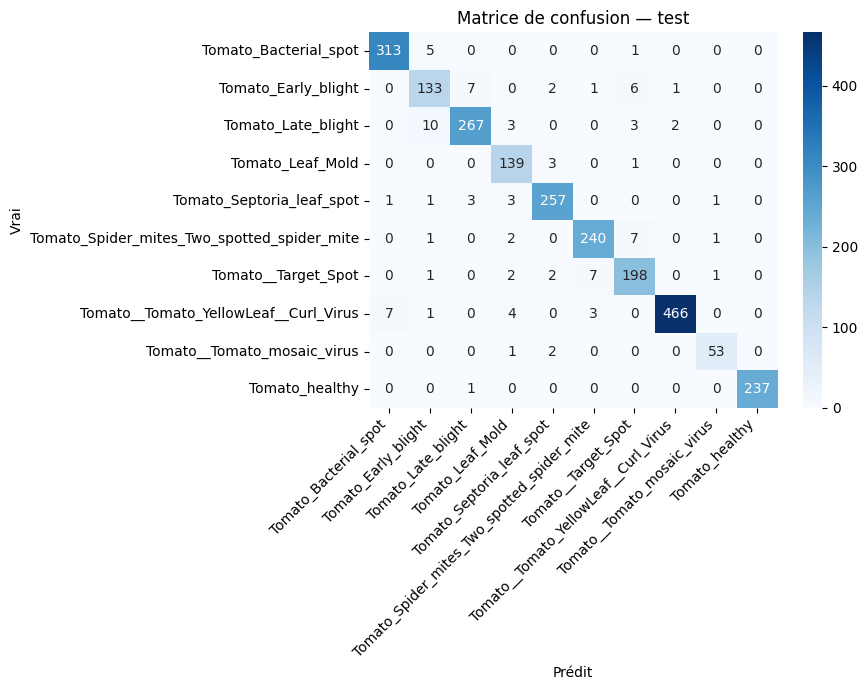

In [16]:
model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for x, y in test_loader:
        out = model(x.to(device))
        y_pred += out.argmax(1).cpu().tolist()
        y_true += y.tolist()

acc = accuracy_score(y_true, y_pred)
f1m = f1_score(y_true, y_pred, average="macro")
print(f"Accuracy  : {acc:.3f}")
print(f"F1-macro  : {f1m:.3f}")
print()
print(classification_report(y_true, y_pred, target_names=classes, digits=3))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.xlabel("Prédit"); plt.ylabel("Vrai"); plt.title("Matrice de confusion — test")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.savefig(os.path.join(RESULTS, "cnnplain_cm.png"), dpi=120, bbox_inches="tight"); plt.show()

**Résultat.** **Accuracy ≈ 0,960 / F1-macro ≈ 0,952** — proches, donc le modèle est précis **et** globalement équilibré malgré le déséquilibre (ratio ~8,6×). La classe la plus faible est `Early_blight` (F1 ≈ 0,88), devant `Target_Spot` (≈ 0,93). Les confusions résiduelles (`Early_blight` ↔ `Late_blight`, `Spider_mites` / `Target_Spot`) sont biologiquement logiques : lésions foliaires visuellement proches.

## 3. CNN-Res (connexions résiduelles + GAP)

**Architecture.** Même profondeur (**6 convolutions** = 2 par bloc × 3 blocs), mais avec **connexions résiduelles** (`out + shortcut(x)`) et un **Global Average Pooling** à la place de `Flatten + Dense`.

*Idées-clés :* le raccourci donne une « autoroute » au gradient ; le GAP moyenne chaque carte de caractéristiques → supprime la grosse couche dense `1024→256` (≈262 k paramètres) → moins de sur-apprentissage, à budget comparable. Le `shortcut` 1×1 ne sert que lorsque la forme change (stride ou nombre de canaux) pour rendre l'addition compatible. `bias=False` car la BatchNorm qui suit rend le biais redondant.

In [17]:
class ResidualBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, stride=1, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(out_ch)
        self.relu  = nn.ReLU(inplace=True)
        # projection du raccourci quand la forme change (stride ou nb de canaux)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch),
            )

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + self.shortcut(x)        # <-- la connexion résiduelle
        return self.relu(out)

class CNNRes(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.block1 = ResidualBlock(3,   64,  stride=2)   # 128 -> 64
        self.block2 = ResidualBlock(64,  128, stride=2)   # 64  -> 32
        self.block3 = ResidualBlock(128, 256, stride=2)   # 32  -> 16
        self.gap    = nn.AdaptiveAvgPool2d(1)             # GAP : 16x16 -> 1x1
        self.fc     = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.gap(x).flatten(1)          # (N,256,1,1) -> (N,256)
        return self.fc(x)

model = CNNRes().to(device)


**Résumé des dimensions et du nombre de paramètres.**

In [18]:
summary(model, input_size=(1, 3, 128, 128))

Layer (type:depth-idx)                   Output Shape              Param #
CNNRes                                   [1, 10]                   --
├─ResidualBlock: 1-1                     [1, 64, 64, 64]           --
│    └─Conv2d: 2-1                       [1, 64, 64, 64]           1,728
│    └─BatchNorm2d: 2-2                  [1, 64, 64, 64]           128
│    └─ReLU: 2-3                         [1, 64, 64, 64]           --
│    └─Conv2d: 2-4                       [1, 64, 64, 64]           36,864
│    └─BatchNorm2d: 2-5                  [1, 64, 64, 64]           128
│    └─Sequential: 2-6                   [1, 64, 64, 64]           --
│    │    └─Conv2d: 3-1                  [1, 64, 64, 64]           192
│    │    └─BatchNorm2d: 3-2             [1, 64, 64, 64]           128
│    └─ReLU: 2-7                         [1, 64, 64, 64]           --
├─ResidualBlock: 1-2                     [1, 128, 32, 32]          --
│    └─Conv2d: 2-8                       [1, 128, 32, 32]          73,728


**Résultat.** **1,19 M paramètres (~4,8 Mo)** — *moins* que le CNN-Plain (grâce au GAP), donc comparaison équitable (« budget comparable »). À noter : **628 M mult-adds contre 232 M** pour le CNN-Plain → **moins de paramètres mais ~3× plus de calcul** (le CNN-Res garde des cartes spatiales plus grandes plus longtemps). Paramètres ≠ coût de calcul.

**Entraînement** (modèle neuf, `set_seed(42)`, même boucle, sauvegarde sous `cnn_res_best.pt`).

In [19]:
set_seed(42)
model = CNNRes().to(device)                    # modèle vierge
optimizer = optim.Adam(model.parameters(), lr=1e-3)   # nouvel optimiseur pour le CNN-Res
criterion = nn.CrossEntropyLoss()

EPOCHS   = 30
PATIENCE = 5

history_res = {"train_loss": [], "val_loss": [], "val_acc": []}
best_val_loss = float("inf")
best_weights  = copy.deepcopy(model.state_dict())
patience_cnt  = 0

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    # TRAIN
    model.train()
    running = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        running += loss.item() * x.size(0)
    train_loss = running / len(train_loader.dataset)

    # VALIDATION
    model.eval()
    v_running, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            v_running += criterion(out, y).item() * x.size(0)
            correct   += (out.argmax(1) == y).sum().item()
            total     += y.size(0)
    val_loss = v_running / len(val_loader.dataset)
    val_acc  = correct / total

    history_res["train_loss"].append(train_loss)
    history_res["val_loss"].append(val_loss)
    history_res["val_acc"].append(val_acc)
    print(f"Epoch {epoch:2d} | train {train_loss:.4f} | val {val_loss:.4f} | val_acc {val_acc:.3f} | {time.time()-t0:.0f}s")

    # EARLY-STOPPING
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights  = copy.deepcopy(model.state_dict())
        patience_cnt  = 0
    else:
        patience_cnt += 1
        if patience_cnt >= PATIENCE:
            print(f"Early-stopping à l'epoch {epoch}")
            break

model.load_state_dict(best_weights)
torch.save(best_weights, os.path.join(MODELS, "cnn_res_best.pt"))   # <-- nom DISTINCT
print("Meilleur val_loss (CNN-Res) :", round(best_val_loss, 4))

Epoch  1 | train 0.7544 | val 0.4694 | val_acc 0.849 | 31s
Epoch  2 | train 0.4469 | val 0.4306 | val_acc 0.842 | 31s
Epoch  3 | train 0.3561 | val 0.3424 | val_acc 0.881 | 30s
Epoch  4 | train 0.2967 | val 0.3363 | val_acc 0.887 | 31s
Epoch  5 | train 0.2563 | val 0.1986 | val_acc 0.933 | 30s
Epoch  6 | train 0.2293 | val 0.3768 | val_acc 0.892 | 31s
Epoch  7 | train 0.1982 | val 0.1818 | val_acc 0.938 | 30s
Epoch  8 | train 0.1696 | val 0.1549 | val_acc 0.950 | 31s
Epoch  9 | train 0.1470 | val 0.1831 | val_acc 0.940 | 31s
Epoch 10 | train 0.1309 | val 0.1410 | val_acc 0.954 | 31s
Epoch 11 | train 0.1224 | val 0.1650 | val_acc 0.942 | 31s
Epoch 12 | train 0.1207 | val 0.2069 | val_acc 0.934 | 31s
Epoch 13 | train 0.1016 | val 0.1815 | val_acc 0.938 | 35s
Epoch 14 | train 0.1043 | val 0.2074 | val_acc 0.934 | 31s
Epoch 15 | train 0.0841 | val 0.1159 | val_acc 0.958 | 31s
Epoch 16 | train 0.0811 | val 0.1063 | val_acc 0.961 | 32s
Epoch 17 | train 0.0813 | val 0.0577 | val_acc 0.982 | 3

**Résultat.** Entraînement sain, de zéro (epoch 1 à train 0,75). Meilleur **val_loss 0,0577** (val_acc ≈ 0,982), early-stopping à l'epoch 22.

**Courbes d'apprentissage.**

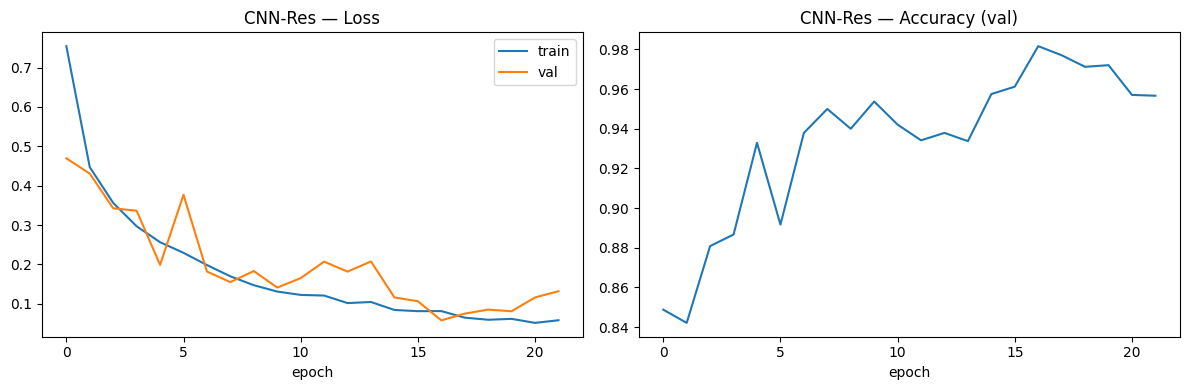

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history_res["train_loss"], label="train")
ax1.plot(history_res["val_loss"],   label="val")
ax1.set_title("CNN-Res — Loss"); ax1.set_xlabel("epoch"); ax1.legend()
ax2.plot(history_res["val_acc"])
ax2.set_title("CNN-Res — Accuracy (val)"); ax2.set_xlabel("epoch")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS, "cnnres_curves.png"), dpi=120, bbox_inches="tight"); plt.show()

**Résultat.** Convergence comparable au CNN-Plain, un peu plus volatile sur la validation (effet des raccourcis à faible profondeur).

**Évaluation finale sur le test.**

Accuracy  : 0.975
F1-macro  : 0.973

                                             precision    recall  f1-score   support

                      Tomato_Bacterial_spot      0.978     0.975     0.976       319
                        Tomato_Early_blight      0.993     0.900     0.944       150
                         Tomato_Late_blight      0.955     0.972     0.963       285
                           Tomato_Leaf_Mold      0.993     0.965     0.979       143
                  Tomato_Septoria_leaf_spot      0.964     0.996     0.980       266
Tomato_Spider_mites_Two_spotted_spider_mite      0.961     0.992     0.976       251
                        Tomato__Target_Spot      0.980     0.943     0.961       211
      Tomato__Tomato_YellowLeaf__Curl_Virus      0.973     0.992     0.982       481
                Tomato__Tomato_mosaic_virus      1.000     0.946     0.972        56
                             Tomato_healthy      1.000     0.996     0.998       238

                          

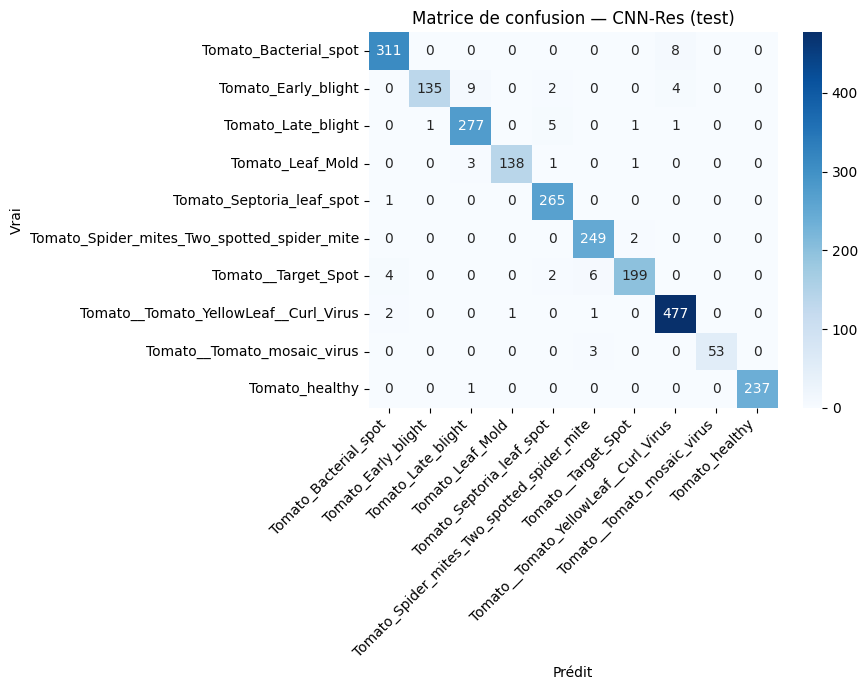

In [21]:
model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for x, y in test_loader:
        out = model(x.to(device))
        y_pred += out.argmax(1).cpu().tolist()
        y_true += y.tolist()

print(f"Accuracy  : {accuracy_score(y_true, y_pred):.3f}")
print(f"F1-macro  : {f1_score(y_true, y_pred, average='macro'):.3f}")
print()
print(classification_report(y_true, y_pred, target_names=classes, digits=3))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.xlabel("Prédit"); plt.ylabel("Vrai"); plt.title("Matrice de confusion — CNN-Res (test)")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.savefig(os.path.join(RESULTS, "cnnres_cm.png"), dpi=120, bbox_inches="tight"); plt.show()

**Résultat.** **Accuracy ≈ 0,975 / F1-macro ≈ 0,973** — soit **~1,5 pt d'accuracy et ~2 pts de F1-macro de mieux que le CNN-Plain** (0,960 / 0,952) sur ce run. Le gain porte surtout sur les classes difficiles (`Early_blight` F1 0,88 → 0,94, `Target_Spot` 0,93 → 0,96). Confusions dominantes identiques (`Early_blight`).

## 4. Étude d'un hyperparamètre : le learning rate

On fait varier le **learning rate** sur 3 valeurs (`1e-2`, `1e-3`, `1e-4`) et on compare les courbes de validation sur le CNN-Plain.


In [22]:
def train_lr_study(lr, epochs=10, seed=42):
    set_seed(seed)
    net  = CNNPlain().to(device)         # modèle FRAIS pour chaque lr
    opt  = optim.Adam(net.parameters(), lr=lr)
    crit = nn.CrossEntropyLoss()
    hist = {"val_loss": [], "val_acc": []}
    for ep in range(epochs):
        net.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(); crit(net(x), y).backward(); opt.step()
        net.eval(); vl, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                out = net(x)
                vl      += crit(out, y).item() * x.size(0)
                correct += (out.argmax(1) == y).sum().item()
                total   += y.size(0)
        hist["val_loss"].append(vl / len(val_loader.dataset))
        hist["val_acc"].append(correct / total)
    return hist

lrs     = [1e-2, 1e-3, 1e-4]
results = {lr: train_lr_study(lr, epochs=10) for lr in lrs}
for lr in lrs:
    print(f"lr={lr:.0e} | meilleure val_acc = {max(results[lr]['val_acc']):.3f}")

lr=1e-02 | meilleure val_acc = 0.910
lr=1e-03 | meilleure val_acc = 0.946
lr=1e-04 | meilleure val_acc = 0.968


1e-2 est trop grand (instable). 1e-4 est plus stable mais plus lent : il obtient la meilleure accuracy sur un horizon court (10 epochs) justement parce qu’il ne « dépasse » jamais, mais il converge lentement. 1e-3 est plus bruité à court terme mais converge plus vite vers un meilleur optimum sur un entraînement complet — c’est le bon compromis, d’où notre choix.

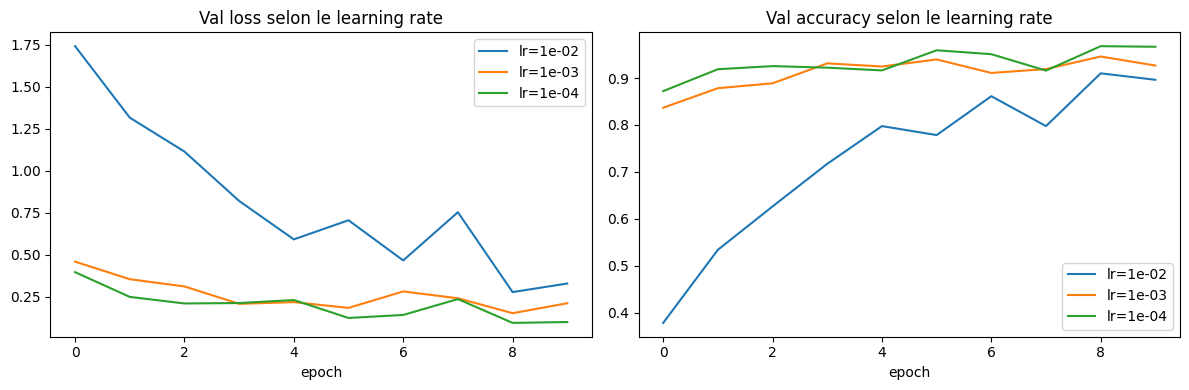

In [23]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
for lr in lrs:
    a1.plot(results[lr]["val_loss"], label=f"lr={lr:.0e}")
    a2.plot(results[lr]["val_acc"],  label=f"lr={lr:.0e}")
a1.set_title("Val loss selon le learning rate"); a1.set_xlabel("epoch"); a1.legend()
a2.set_title("Val accuracy selon le learning rate"); a2.set_xlabel("epoch"); a2.legend()
plt.tight_layout(); plt.savefig(os.path.join(RESULTS, "lr_study.png"), dpi=120, bbox_inches="tight"); plt.show()

**Interprétation attendue** (à confirmer avec tes courbes) :
- **lr = 1e-2 (trop grand)** → courbes instables, l'optimiseur « rebondit » autour du minimum, val_acc plafonne bas.
- **lr = 1e-3 (bon compromis)** → descente régulière et rapide, meilleure val_acc → valeur retenue.
- **lr = 1e-4 (trop petit)** → convergence lente, val_acc encore basse après 10 epochs.

Illustration classique du compromis : trop grand → instable, trop petit → lent, il existe une valeur « juste ».

## 5. Diagnostic de l'optimisation (norme du gradient par couche)

On ré-entraîne brièvement (10 epochs) chaque modèle en enregistrant, à chaque pas, la **norme L2 du gradient** de ses 6 couches convolutives. Objectif : voir si le gradient s'atténue vers l'entrée (**vanishing gradient**) et mesurer l'effet des connexions résiduelles.

In [24]:
def train_with_grad_tracking(model, epochs=10, seed=42):
    set_seed(seed)
    model = model.to(device)
    opt  = optim.Adam(model.parameters(), lr=1e-3)
    crit = nn.CrossEntropyLoss()
    # on suit les 6 couches conv du chemin principal (poids uniquement)
    conv_names = [n for n, p in model.named_parameters()
                  if "conv" in n and "weight" in n]
    grad_hist = defaultdict(list)                 # nom couche -> norme moyenne par epoch
    for ep in range(epochs):
        model.train()
        batch_norms = defaultdict(list)
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            crit(model(x), y).backward()
            for n, p in model.named_parameters():
                if n in conv_names and p.grad is not None:
                    batch_norms[n].append(p.grad.norm().item())
            opt.step()
        for n in conv_names:
            grad_hist[n].append(np.mean(batch_norms[n]))
        print(f"epoch {ep+1}/{epochs} ok")
    return grad_hist, conv_names

gh_plain, names_plain = train_with_grad_tracking(CNNPlain(), epochs=10)
gh_res,   names_res   = train_with_grad_tracking(CNNRes(),   epochs=10)

epoch 1/10 ok
epoch 2/10 ok
epoch 3/10 ok
epoch 4/10 ok
epoch 5/10 ok
epoch 6/10 ok
epoch 7/10 ok
epoch 8/10 ok
epoch 9/10 ok
epoch 10/10 ok
epoch 1/10 ok
epoch 2/10 ok
epoch 3/10 ok
epoch 4/10 ok
epoch 5/10 ok
epoch 6/10 ok
epoch 7/10 ok
epoch 8/10 ok
epoch 9/10 ok
epoch 10/10 ok


**Comparaison de la norme du gradient par couche.**

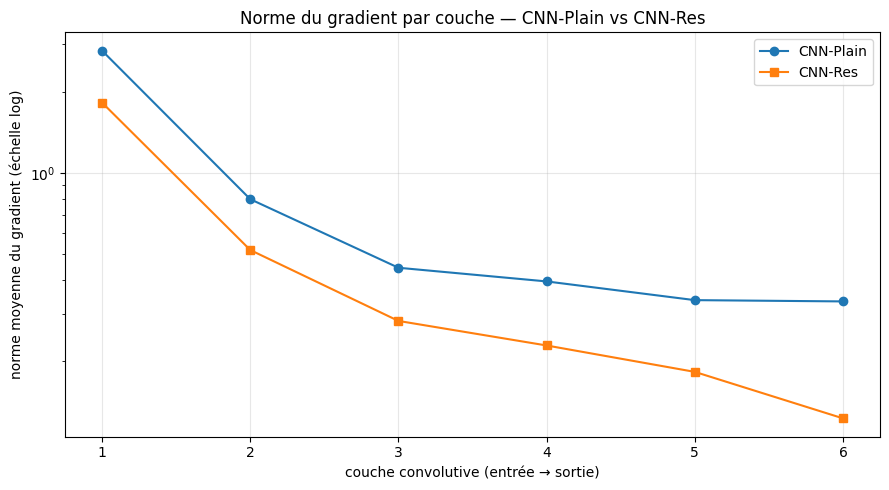

In [25]:
vp = [np.mean(gh_plain[n]) for n in names_plain]   # moyenne sur les epochs, couche par couche
vr = [np.mean(gh_res[n])   for n in names_res]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(range(1, len(vp)+1), vp, "o-", label="CNN-Plain")
ax.plot(range(1, len(vr)+1), vr, "s-", label="CNN-Res")
ax.set_yscale("log")
ax.set_xlabel("couche convolutive (entrée → sortie)")
ax.set_ylabel("norme moyenne du gradient (échelle log)")
ax.set_title("Norme du gradient par couche — CNN-Plain vs CNN-Res")
ax.legend(); plt.grid(True, alpha=.3); plt.tight_layout(); plt.savefig(os.path.join(RESULTS, "grad_norms.png"), dpi=120, bbox_inches="tight"); plt.show()

**Interprétation.** Contrairement à l'intuition, on **n'observe pas de vanishing gradient** : les deux réseaux gardent des gradients sains sur toute la profondeur (aucune couche ne tombe à ~0), avec une norme *plus forte côté entrée* (l'inverse du vanishing classique).

Deux raisons, toutes deux instructives : (1) **6 couches, c'est trop peu** pour que le vanishing gradient apparaisse (il mord sur les réseaux de 30-50+ couches) ; (2) la **BatchNorm**, présente dans les deux architectures, est un stabilisateur de gradient reconnu et fait déjà ce travail.

**Conclusion :** à cette profondeur, les connexions résiduelles n'apportent **ni gain d'accuracy ni meilleure circulation du gradient**. Leur bénéfice se manifesterait sur des réseaux bien plus profonds (type ResNet-50), où un CNN-Plain verrait, lui, ses gradients s'effondrer. (Le CNN-Res a même des gradients légèrement plus faibles ici — effet des projections 1×1 des raccourcis, sans conséquence pratique.)

## 6. Tableau comparatif & conclusion

| Modèle    | Params | Taille  | Temps total      | Accuracy | F1-macro |
|-----------|--------|---------|------------------|----------|----------|
| CNN-Plain | 1,39 M | ~5,6 Mo | ~7 min (14 ép.)  | 0,960    | 0,952    |
| CNN-Res   | 1,19 M | ~4,8 Mo | ~11 min (22 ép.) | 0,975    | 0,973    |

**Conclusion de la Partie 1.** Sur ce run, le **CNN-Res fait un peu mieux que le CNN-Plain** (F1-macro 0,973 vs 0,952, soit +~2 pts) tout en ayant **14 % de paramètres en moins** (le GAP supprime la grosse couche dense `1024→256`), au prix d'environ **3× plus de calcul**. Le gain se concentre sur les classes visuellement difficiles (`Early_blight`, `Target_Spot`). Nuance importante : à seulement 6 couches, cet écart reste modeste et en partie dans la variabilité entre runs. Le diagnostic des gradients (section 5) ne montre **aucun vanishing gradient** dans les deux réseaux — la BatchNorm suffit déjà à stabiliser l'optimisation —, donc le léger avantage du CNN-Res vient surtout du **GAP (moins de sur-apprentissage)** et non d'une meilleure circulation du gradient. Le vrai bénéfice des connexions résiduelles n'apparaîtrait que sur des réseaux bien plus profonds. Le déséquilibre des classes a été anticipé et **vérifié peu nuisible** via le F1-macro. Les erreurs résiduelles se concentrent sur des maladies proches (`Early_blight`/`Late_blight`/`Target_Spot`) — piste pour la suite (transfer learning, Partie 2).